# 04 — COVID-19 Volatility Treatment

## What this notebook does
1. **Diagnose exceptional COVID-19 volatility** — examine reduced-form residuals across the 16 country-origin systems
2. **Compare alternative COVID treatments** — evaluate homoskedastic, deterministic-dummy and two-stage truncated-volatility specifications under a common BVAR setup
3. **Estimate COVID volatility parameters** — estimate the truncated-volatility parameters by concentrated maximum likelihood for each system
4. **Assess the persistence parameter** — use profile likelihoods to evaluate the estimated post-pandemic volatility persistence
5. **Freeze production inputs** — export the estimated volatility parameters and scale paths used by the main BVAR in notebook 05

## Role in the empirical pipeline
The COVID-19 period contains unusually large innovations that are difficult to reconcile with a constant-variance specification. The analysis does not remove pandemic observations or alter the observed values of the variables. Instead, the selected specification allows the innovation variance to increase temporarily during the pandemic period.

Three specifications are compared under the same sample, lag length, Minnesota hyperparameters, prior on the covariance matrix, Cholesky ordering, posterior draws and IRF horizons:

1. Homoskedastic BVAR
2. BVAR with deterministic dummies for 2020Q2–2020Q3
3. Two-stage truncated-volatility BVAR

The final production specification uses the **two-stage truncated-volatility treatment**, with the estimated scale paths subsequently treated as fixed inputs in notebook 05.


In [1]:
# ============================================================
# A. SETUP AND FROZEN CONFIGURATION
# ============================================================
from pathlib import Path
from itertools import product
import warnings

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.optimize import minimize

warnings.filterwarnings("ignore", category=FutureWarning)

# Support both Google Colab and local execution
try:
    from google.colab import drive
    drive.mount("/content/drive")
    PROJECT_ROOT = Path("/content/drive/MyDrive/TFM_GitHub")
except ImportError:
    PROJECT_ROOT = Path.cwd().resolve()
    if PROJECT_ROOT.name == "notebooks":
        PROJECT_ROOT = PROJECT_ROOT.parent

if not (PROJECT_ROOT / "notebooks").exists():
    raise FileNotFoundError(
        f"Could not find the project under: {PROJECT_ROOT}"
    )

PROCESSED_DIR = PROJECT_ROOT / "data" / "processed"
OUTPUT_DIR = PROJECT_ROOT / "outputs" / "04_covid_volatility"
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

BVAR_READY_PATH = PROCESSED_DIR / "03_bvar_ready_panel.xlsx"
if not BVAR_READY_PATH.exists():
    raise FileNotFoundError(
        "BVAR-ready panel not found. Run notebook 03 first: "
        f"{BVAR_READY_PATH}"
    )

panel = pd.read_excel(BVAR_READY_PATH)
panel["quarter"] = pd.PeriodIndex(panel["quarter"].astype(str), freq="Q")

TARGET_COUNTRIES = ["Germany", "France", "Italy", "Spain"]
GPR_ORIGIN_COLS = {
    "Russia": "log1p_GPR_Russia",
    "China": "log1p_GPR_China",
    "MENA": "log1p_GPR_Middle_East",
    "Western": "log1p_GPR_Western_Bloc",
}
ORIGINS = list(GPR_ORIGIN_COLS.keys())
GPR_ORIGINS_COLS = list(GPR_ORIGIN_COLS.values())
CHOLESKY_ORDER_CORE = [
    "dlog_Brent",
    "dlog_Gas",
    "dlog_HICP",
    "dlog_IPI",
    "CLIFS_level",
]

LAG = 2
IRF_HORIZON = 20
CI_LOW_68, CI_HIGH_68 = 16, 84

# Minnesota prior
LAM1, LAM2, LAM3, LAM4 = 0.2, 0.5, 1.0, 100.0
EXOG_TIGHTNESS = LAM4

# Diffuse/reference treatment for Sigma
SIGMA_PRIOR_SCALE = 0.0
ALPHA = 0

# COVID alternatives
COVID_DUMMY_QUARTERS = ["2020Q2", "2020Q3"]
COVID_VOL_FREE_QUARTERS = ["2020Q1", "2020Q2", "2020Q3"]
COVID_VOL_TRUNCATE_FROM = "2021Q4"
SCALE_LOWER, SCALE_UPPER = 1.0, 50.0
RHO_LOWER, RHO_UPPER = 0.0, 0.999

# Gibbs settings used only for the ceteris-paribus treatment comparison.
QUICK_TEST = False
REPS = 2000 if QUICK_TEST else 10000
BURN = 1000 if QUICK_TEST else 5000
SEED = 42

expected_cols = ["quarter", "country"] + GPR_ORIGINS_COLS + CHOLESKY_ORDER_CORE
missing_cols = [c for c in expected_cols if c not in panel.columns]
if missing_cols:
    raise KeyError(f"Required columns missing from notebook 03 output: {missing_cols}")

print(f"Panel: {panel.shape[0]} rows x {panel.shape[1]} columns")
print(f"Sample: {panel['quarter'].min()} to {panel['quarter'].max()}")
print(f"Lags: {LAG}")
print(f"Gibbs: {REPS:,} reps, {BURN:,} burn-in")
print(f"Minnesota lambdas: {LAM1}, {LAM2}, {LAM3}, {LAM4}")
print(f"Sigma prior: S={SIGMA_PRIOR_SCALE:g}, alpha={ALPHA}")
print(f"COVID dummies: {COVID_DUMMY_QUARTERS}")
print("Ordering: [GPR, Brent, Gas, HICP, IPI, CLIFS]")


Mounted at /content/drive
Panel: 460 rows x 11 columns
Sample: 1997Q2 to 2025Q4
Lags: 2
Gibbs: 10,000 reps, 5,000 burn-in
Minnesota lambdas: 0.2, 0.5, 1.0, 100.0
Sigma prior: S=0, alpha=0
COVID dummies: ['2020Q2', '2020Q3']
Ordering: [GPR, Brent, Gas, HICP, IPI, CLIFS]


In [2]:
# ============================================================
# B. REDUCED-FORM HELPERS
# ============================================================
def system_frame(country, gpr_col):
    sub = (
        panel[panel["country"] == country]
        .sort_values("quarter")
        .reset_index(drop=True)
    )
    var_order = [gpr_col] + CHOLESKY_ORDER_CORE
    return sub[["quarter"] + var_order].dropna().reset_index(drop=True), var_order


def build_var_xy(Y, p, Z=None):
    T, n = Y.shape
    X_parts = [np.ones(T - p)]
    X_parts += [Y[p - lag:T - lag] for lag in range(1, p + 1)]

    if Z is not None:
        Z = np.asarray(Z, dtype=float)
        if Z.ndim == 1:
            Z = Z[:, None]
        if Z.shape[0] != T:
            raise ValueError("Z must have the same number of rows as Y.")
        X_parts.append(Z[p:])

    return np.column_stack(X_parts), Y[p:]


def estimate_var_ols(Y, p, Z=None):
    X, Ydep = build_var_xy(Y, p, Z=Z)
    Beta = np.linalg.lstsq(X, Ydep, rcond=None)[0]
    U = Ydep - X @ Beta
    Sigma = (U.T @ U) / len(Ydep)
    return Beta, U, Sigma, X, Ydep


def estimate_ar1(x):
    x = np.asarray(x, dtype=float)
    X = np.column_stack([np.ones(len(x) - 1), x[:-1]])
    return float(np.linalg.lstsq(X, x[1:], rcond=None)[0][1])


def build_covid_dummies(quarters):
    q = pd.Series(quarters).astype(str)
    return np.column_stack([
        (q == covid_q).astype(float).to_numpy()
        for covid_q in COVID_DUMMY_QUARTERS
    ])


Residual diagnostic, 2019Q1–2022Q4:


,quarter,mean_mahalanobis,max_mahalanobis,systems_above_95pct,systems_above_99pct,mean_max_abs_std_resid
85,2019Q1,2.751321,3.271702,0,0,1.524795
86,2019Q2,2.431476,2.912442,0,0,1.616952
87,2019Q3,1.493528,2.020118,0,0,0.958130
88,2019Q4,1.930578,2.493624,0,0,1.150867
89,2020Q1,4.044514,4.709914,3,0,3.372395
90,2020Q2,6.415213,7.132348,16,12,6.064949
91,2020Q3,5.203236,6.451678,16,0,4.982189
92,2020Q4,2.189498,3.027245,0,0,1.855273
93,2021Q1,2.429560,3.272242,0,0,1.982663
94,2021Q2,2.307552,3.704925,0,0,1.443715


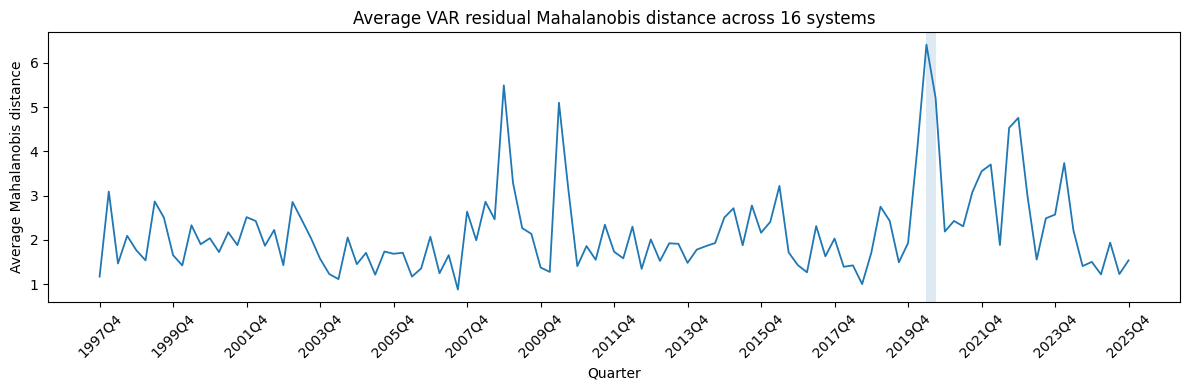

In [3]:
# ============================================================
# C1. REDUCED-FORM COVID DIAGNOSTIC
# ============================================================
residual_rows = []

for country in TARGET_COUNTRIES:
    for origin, gpr_col in GPR_ORIGIN_COLS.items():
        df, var_order = system_frame(country, gpr_col)
        Y = df[var_order].to_numpy(dtype=float)

        _, U, Sigma, _, _ = estimate_var_ols(Y, LAG)
        residual_quarters = df["quarter"].astype(str).iloc[LAG:].reset_index(drop=True)
        invSigma = np.linalg.inv(Sigma)

        mahal_sq = np.einsum("ij,jk,ik->i", U, invSigma, U)
        mahal = np.sqrt(np.maximum(mahal_sq, 0.0))
        mahal_pct = pd.Series(mahal).rank(method="average", pct=True).to_numpy() * 100
        std_resid = U / np.sqrt(np.diag(Sigma))

        for t in range(len(U)):
            residual_rows.append({
                "country": country,
                "gpr_origin": origin,
                "quarter": residual_quarters.iloc[t],
                "mahalanobis": float(mahal[t]),
                "mahalanobis_percentile": float(mahal_pct[t]),
                "max_abs_std_residual": float(np.max(np.abs(std_resid[t]))),
            })

residual_diag = pd.DataFrame(residual_rows)
quarter_summary = (
    residual_diag.groupby("quarter")
    .agg(
        mean_mahalanobis=("mahalanobis", "mean"),
        max_mahalanobis=("mahalanobis", "max"),
        systems_above_95pct=("mahalanobis_percentile", lambda x: int((x >= 95).sum())),
        systems_above_99pct=("mahalanobis_percentile", lambda x: int((x >= 99).sum())),
        mean_max_abs_std_resid=("max_abs_std_residual", "mean"),
    )
    .reset_index()
)

print("Residual diagnostic, 2019Q1–2022Q4:")
display(quarter_summary[quarter_summary["quarter"].between("2019Q1", "2022Q4")])

residual_diag.to_csv(OUTPUT_DIR / "01_residual_diagnostic_all_quarters.csv", index=False)
quarter_summary.to_csv(OUTPUT_DIR / "02_residual_diagnostic_by_quarter.csv", index=False)

fig, ax = plt.subplots(figsize=(12, 4))
x = np.arange(len(quarter_summary))
ax.plot(x, quarter_summary["mean_mahalanobis"], linewidth=1.3)
q2 = quarter_summary.index[quarter_summary["quarter"] == "2020Q2"].tolist()
q3 = quarter_summary.index[quarter_summary["quarter"] == "2020Q3"].tolist()
if q2 and q3:
    ax.axvspan(q2[0], q3[0], alpha=0.15)
tick_idx = np.arange(0, len(quarter_summary), 8)
ax.set_xticks(tick_idx)
ax.set_xticklabels(quarter_summary.loc[tick_idx, "quarter"], rotation=45)
ax.set_title("Average VAR residual Mahalanobis distance across 16 systems")
ax.set_xlabel("Quarter")
ax.set_ylabel("Average Mahalanobis distance")
plt.tight_layout()
plt.savefig(OUTPUT_DIR / "03_mahalanobis_over_time.png", dpi=150, bbox_inches="tight")
plt.show()


In [4]:
# ============================================================
# C2. RESIDUAL-VARIANCE EFFECT OF COVID DUMMIES
# ============================================================
#
# Descriptive diagnostic only.
# Measures how much the full-sample residual standard deviation
# falls after controlling for deterministic 2020Q2–2020Q3 dummies.
#
# This is NOT used for model selection.
# ============================================================

variance_rows = []

for country in TARGET_COUNTRIES:

    for gpr_col in GPR_ORIGINS_COLS:

        origin = gpr_col.replace(
            "log1p_GPR_",
            ""
        )

        df, var_order = system_frame(
            country,
            gpr_col
        )

        Y = df[
            var_order
        ].to_numpy(
            dtype=float
        )

        quarters = (
            df["quarter"]
            .astype(str)
            .reset_index(drop=True)
        )

        # ----------------------------------------------------
        # Baseline homoskedastic VAR
        # ----------------------------------------------------
        _, _, Sigma_base, _, _ = estimate_var_ols(
            Y,
            LAG,
            Z=None
        )

        # ----------------------------------------------------
        # VAR with deterministic COVID dummies
        # ----------------------------------------------------
        Z_covid = build_covid_dummies(
            quarters
        )

        _, _, Sigma_covid, _, _ = estimate_var_ols(
            Y,
            LAG,
            Z=Z_covid
        )

        # ----------------------------------------------------
        # Residual standard deviations
        # ----------------------------------------------------
        sd_base = np.sqrt(
            np.diag(Sigma_base)
        )

        sd_covid = np.sqrt(
            np.diag(Sigma_covid)
        )

        for j, variable in enumerate(
            var_order
        ):

            variance_rows.append({
                "country": country,
                "gpr_origin": origin,
                "variable": variable,
                "residual_SD_reduction_pct":
                    100
                    * (
                        1
                        - sd_covid[j]
                        / sd_base[j]
                    ),
            })


variance_diag = pd.DataFrame(
    variance_rows
)


# ============================================================
# Median reduction across the 16 systems
# ============================================================

variable_covid_effect = (
    variance_diag
    .groupby(
        "variable"
    )[
        "residual_SD_reduction_pct"
    ]
    .median()
    .sort_values(
        ascending=False
    )
    .to_frame(
        "median_residual_SD_reduction_pct"
    )
)


print(
    "Residual SD reduction after controlling "
    "for 2020Q2–2020Q3 dummies:"
)

display(
    variable_covid_effect.round(2)
)

Residual SD reduction after controlling for 2020Q2–2020Q3 dummies:


,median_residual_SD_reduction_pct
variable,
dlog_IPI,51.36
dlog_Gas,8.55
dlog_Brent,7.30
CLIFS_level,2.04
log1p_GPR_Middle_East,1.95
dlog_HICP,1.23
log1p_GPR_Russia,0.80
log1p_GPR_Western_Bloc,0.32
log1p_GPR_China,0.06


In [5]:
# ============================================================
# D1. TRUNCATED VOLATILITY PATH + TWO-STAGE MLE
# ============================================================
def build_truncated_covid_scale_path(quarters, s0, s1, s2, rho):
    periods = pd.PeriodIndex(pd.Series(quarters).astype(str), freq="Q")
    path = np.ones(len(periods), dtype=float)

    q0 = pd.Period("2020Q1", freq="Q")
    q1 = pd.Period("2020Q2", freq="Q")
    q2 = pd.Period("2020Q3", freq="Q")
    trunc = pd.Period(COVID_VOL_TRUNCATE_FROM, freq="Q")

    for idx, q in enumerate(periods):
        if q == q0:
            path[idx] = s0
        elif q == q1:
            path[idx] = s1
        elif q == q2:
            path[idx] = s2
        elif q > q2 and q < trunc:
            j = q.ordinal - q2.ordinal
            path[idx] = 1.0 + (s2 - 1.0) * (rho ** j)
        else:
            path[idx] = 1.0

    return path


def concentrated_negloglik(theta, Y, quarters, p):
    s0, s1, s2, rho = np.asarray(theta, dtype=float)
    if s0 < 1 or s1 < 1 or s2 < 1 or rho < 0 or rho >= 1:
        return np.inf

    X, Ydep = build_var_xy(Y, p, Z=None)
    T_eff, n = Ydep.shape
    full_scale = build_truncated_covid_scale_path(quarters, s0, s1, s2, rho)
    s_eff = np.asarray(full_scale[p:], dtype=float)

    X_star = X / s_eff[:, None]
    Y_star = Ydep / s_eff[:, None]
    Beta_hat = np.linalg.lstsq(X_star, Y_star, rcond=None)[0]
    U_star = Y_star - X_star @ Beta_hat
    Sigma_hat = (U_star.T @ U_star) / T_eff
    Sigma_hat = (Sigma_hat + Sigma_hat.T) / 2

    sign, logdet = np.linalg.slogdet(Sigma_hat)
    if sign <= 0 or not np.isfinite(logdet):
        return np.inf

    return float(0.5 * T_eff * logdet + n * np.sum(np.log(s_eff)))


def covid_theta_initial_guess(Y, quarters, p):
    _, U, Sigma, _, _ = estimate_var_ols(Y, p, Z=None)
    residual_quarters = pd.Series(quarters).astype(str).iloc[p:].reset_index(drop=True)
    invSigma = np.linalg.inv(Sigma)
    quad = np.einsum("ij,jk,ik->i", U, invSigma, U)
    n = Y.shape[1]

    s_init = []
    for q in COVID_VOL_FREE_QUARTERS:
        mask = (residual_quarters == q).to_numpy()
        scale_guess = np.sqrt(np.mean(quad[mask]) / n) if mask.any() else 1.05
        s_init.append(max(1.05, float(scale_guess)))

    return np.array([s_init[0], s_init[1], s_init[2], 0.50])


def estimate_covid_theta_mle(Y, quarters, p):
    base = covid_theta_initial_guess(Y, quarters, p)
    starts = [
        base,
        np.array([1.10, 4.00, 4.00, 0.20]),
        np.array([1.50, 5.00, 5.00, 0.50]),
        np.array([2.00, 6.00, 5.00, 0.80]),
        np.array([1.05, 3.00, 3.00, 0.05]),
    ]
    bounds = [
        (SCALE_LOWER, SCALE_UPPER),
        (SCALE_LOWER, SCALE_UPPER),
        (SCALE_LOWER, SCALE_UPPER),
        (RHO_LOWER, RHO_UPPER),
    ]

    best = None
    for start in starts:
        res = minimize(
            concentrated_negloglik,
            x0=start,
            args=(Y, quarters, p),
            method="L-BFGS-B",
            bounds=bounds,
            options={"maxiter": 2000, "ftol": 1e-12},
        )
        if np.isfinite(res.fun) and (best is None or res.fun < best.fun):
            best = res

    if best is None:
        raise RuntimeError("COVID volatility MLE failed for all starting values.")

    return {
        "theta_hat": np.asarray(best.x, dtype=float),
        "objective": float(best.fun),
        "success": bool(best.success),
        "message": str(best.message),
    }


In [6]:
# ============================================================
# D2. ESTIMATE THETA AND SCALE PATHS — 16 SYSTEMS
# ============================================================
theta_rows, scale_path_rows, theta_results = [], [], {}

for country in TARGET_COUNTRIES:
    for origin, gpr_col in GPR_ORIGIN_COLS.items():
        df, var_order = system_frame(country, gpr_col)
        Y = df[var_order].to_numpy(dtype=float)
        quarters = df["quarter"].astype(str).reset_index(drop=True)

        fit = estimate_covid_theta_mle(Y, quarters, LAG)
        s0, s1, s2, rho = fit["theta_hat"]
        theta_results[(country, origin)] = fit

        theta_rows.append({
            "country": country,
            "gpr_origin": origin,
            "s0_2020Q1": s0,
            "s1_2020Q2": s1,
            "s2_2020Q3": s2,
            "rho": rho,
            "objective": fit["objective"],
            "optimizer_success": fit["success"],
            "optimizer_message": fit["message"],
        })

        scale_path = build_truncated_covid_scale_path(quarters, s0, s1, s2, rho)
        for q, scale in zip(quarters, scale_path):
            scale_path_rows.append({
                "country": country,
                "gpr_origin": origin,
                "quarter": q,
                "s_t": float(scale),
            })

        print(
            f"{country:8s} - {origin:7s} | "
            f"s0={s0:.3f}, s1={s1:.3f}, s2={s2:.3f}, rho={rho:.3f} | "
            f"success={fit['success']}"
        )

theta_table = pd.DataFrame(theta_rows)
scale_paths = pd.DataFrame(scale_path_rows)

display(theta_table)
theta_table.to_csv(OUTPUT_DIR / "04_covid_theta_mle_by_system.csv", index=False)
scale_paths.to_csv(OUTPUT_DIR / "05_covid_scale_paths_by_system.csv", index=False)

path_summary = (
    scale_paths.groupby("quarter")["s_t"]
    .agg(median_s="median", mean_s="mean", min_s="min", max_s="max")
    .reset_index()
)
display(path_summary[path_summary["quarter"].between("2019Q4", "2022Q1")])


Germany  - Russia  | s0=1.632, s1=5.177, s2=5.716, rho=0.580 | success=True
Germany  - China   | s0=1.664, s1=5.072, s2=5.566, rho=0.554 | success=True
Germany  - MENA    | s0=1.632, s1=5.618, s2=5.785, rho=0.579 | success=True
Germany  - Western | s0=1.651, s1=5.158, s2=5.563, rho=0.570 | success=True
France   - Russia  | s0=2.660, s1=7.065, s2=8.199, rho=0.000 | success=True
France   - China   | s0=2.714, s1=6.833, s2=8.094, rho=0.000 | success=True
France   - MENA    | s0=2.567, s1=7.072, s2=8.010, rho=0.000 | success=True
France   - Western | s0=2.616, s1=6.934, s2=8.047, rho=0.000 | success=True
Italy    - Russia  | s0=2.867, s1=5.080, s2=9.280, rho=0.000 | success=True
Italy    - China   | s0=2.923, s1=4.929, s2=8.976, rho=0.000 | success=True
Italy    - MENA    | s0=2.808, s1=5.357, s2=9.060, rho=0.000 | success=True
Italy    - Western | s0=2.842, s1=5.137, s2=9.159, rho=0.000 | success=True
Spain    - Russia  | s0=2.241, s1=6.033, s2=8.234, rho=0.000 | success=True
Spain    - C

,country,gpr_origin,s0_2020Q1,s1_2020Q2,s2_2020Q3,rho,objective,optimizer_success,optimizer_message
0,Germany,Russia,1.631550,5.177281,5.715587,0.579922,-1983.193208,True,CONVERGENCE: RELATIVE REDUCTION OF F <= FACTR*...
1,Germany,China,1.663806,5.071832,5.566455,0.554092,-1960.228990,True,CONVERGENCE: RELATIVE REDUCTION OF F <= FACTR*...
2,Germany,MENA,1.631664,5.618185,5.785225,0.578710,-2014.047384,True,CONVERGENCE: RELATIVE REDUCTION OF F <= FACTR*...
3,Germany,Western,1.651357,5.157714,5.562562,0.570357,-2033.273873,True,CONVERGENCE: RELATIVE REDUCTION OF F <= FACTR*...
4,France,Russia,2.659586,7.064961,8.198609,0.000000,-2060.467613,True,CONVERGENCE: RELATIVE REDUCTION OF F <= FACTR*...
5,France,China,2.713730,6.832857,8.093807,0.000000,-2089.726774,True,CONVERGENCE: NORM OF PROJECTED GRADIENT <= PGTOL
6,France,MENA,2.566537,7.072005,8.009527,0.000000,-2097.923568,True,CONVERGENCE: RELATIVE REDUCTION OF F <= FACTR*...
7,France,Western,2.615877,6.933863,8.046779,0.000000,-2129.029234,True,CONVERGENCE: NORM OF PROJECTED GRADIENT <= PGTOL
8,Italy,Russia,2.866905,5.079627,9.279866,0.000000,-1953.312903,True,CONVERGENCE: RELATIVE REDUCTION OF F <= FACTR*...
9,Italy,China,2.923388,4.929385,8.975993,0.000000,-1949.856404,True,CONVERGENCE: RELATIVE REDUCTION OF F <= FACTR*...


,quarter,median_s,mean_s,min_s,max_s
90,2019Q4,1.000000,1.000000,1.000000,1.000000
91,2020Q1,2.444457,2.349250,1.631550,2.923388
92,2020Q2,5.800440,5.876640,4.929385,7.072005
93,2020Q3,8.146208,7.783901,5.562562,9.279866
94,2020Q4,1.000000,1.664778,1.000000,3.769256
95,2021Q1,1.000000,1.379669,1.000000,2.602595
96,2021Q2,1.000000,1.216906,1.000000,1.927437
97,2021Q3,1.000000,1.123958,1.000000,1.536717
98,2021Q4,1.000000,1.000000,1.000000,1.000000
99,2022Q1,1.000000,1.000000,1.000000,1.000000


Germany  - Russia  | rho_MLE=0.580 | profile minimum=0.60
Germany  - China   | rho_MLE=0.554 | profile minimum=0.55
Germany  - MENA    | rho_MLE=0.579 | profile minimum=0.60
Germany  - Western | rho_MLE=0.570 | profile minimum=0.55
France   - Russia  | rho_MLE=0.000 | profile minimum=0.00
France   - China   | rho_MLE=0.000 | profile minimum=0.00
France   - MENA    | rho_MLE=0.000 | profile minimum=0.00
France   - Western | rho_MLE=0.000 | profile minimum=0.00
Italy    - Russia  | rho_MLE=0.000 | profile minimum=0.00
Italy    - China   | rho_MLE=0.000 | profile minimum=0.00
Italy    - MENA    | rho_MLE=0.000 | profile minimum=0.00
Italy    - Western | rho_MLE=0.000 | profile minimum=0.00
Spain    - Russia  | rho_MLE=0.000 | profile minimum=0.00
Spain    - China   | rho_MLE=0.000 | profile minimum=0.00
Spain    - MENA    | rho_MLE=0.000 | profile minimum=0.00
Spain    - Western | rho_MLE=0.000 | profile minimum=0.00


,country,gpr_origin,rho_MLE,rho_profile_min,delta_nll_rho_0.00,2delta_nll_rho_0.00,delta_nll_rho_0.10,2delta_nll_rho_0.10,delta_nll_rho_0.20,2delta_nll_rho_0.20,delta_nll_rho_0.30,2delta_nll_rho_0.30
0,Germany,Russia,0.579922,0.60,5.694320,11.388640,5.580276,11.160552,4.382843,8.765687,2.730888,5.461775
1,Germany,China,0.554092,0.55,3.866923,7.733845,3.654826,7.309651,2.778338,5.556676,1.711947,3.423894
2,Germany,MENA,0.578710,0.60,6.224733,12.449467,6.178873,12.357746,4.771704,9.543407,2.874634,5.749269
3,Germany,Western,0.570357,0.55,4.861942,9.723883,4.691226,9.382453,3.622254,7.244507,2.237533,4.475066
4,France,Russia,0.000000,0.00,0.000000,0.000000,0.916402,1.832803,1.274850,2.549700,1.633425,3.266850
5,France,China,0.000000,0.00,0.000000,0.000000,0.773719,1.547439,0.937307,1.874615,1.127873,2.255746
6,France,MENA,0.000000,0.00,0.000000,0.000000,0.714660,1.429321,0.940648,1.881296,1.232935,2.465870
7,France,Western,0.000000,0.00,0.000000,0.000000,0.695264,1.390528,0.828702,1.657404,0.964817,1.929634
8,Italy,Russia,0.000000,0.00,0.000000,0.000000,1.632833,3.265665,3.080028,6.160056,4.906539,9.813078
9,Italy,China,0.000000,0.00,0.000000,0.000000,1.769409,3.538818,3.297781,6.595561,5.131029,10.262059


Systems with rho_MLE = 0:


,country,gpr_origin,rho_MLE,rho_profile_min,delta_nll_rho_0.00,delta_nll_rho_0.10,delta_nll_rho_0.20,delta_nll_rho_0.30
4,France,Russia,0.0,0.0,0.0,0.916402,1.274850,1.633425
5,France,China,0.0,0.0,0.0,0.773719,0.937307,1.127873
6,France,MENA,0.0,0.0,0.0,0.714660,0.940648,1.232935
7,France,Western,0.0,0.0,0.0,0.695264,0.828702,0.964817
8,Italy,Russia,0.0,0.0,0.0,1.632833,3.080028,4.906539
9,Italy,China,0.0,0.0,0.0,1.769409,3.297781,5.131029
10,Italy,MENA,0.0,0.0,0.0,1.881961,3.464245,5.201826
11,Italy,Western,0.0,0.0,0.0,1.557983,2.932054,4.650195
12,Spain,Russia,0.0,0.0,0.0,1.461802,2.520766,3.801676
13,Spain,China,0.0,0.0,0.0,1.643610,2.821111,4.109253


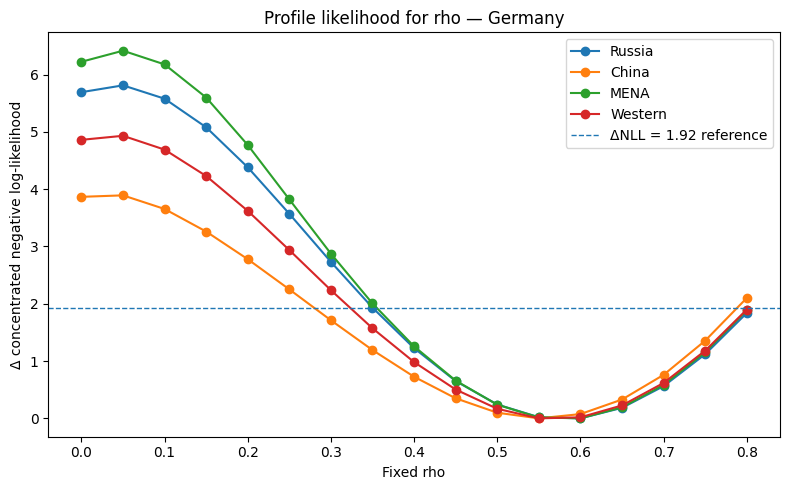

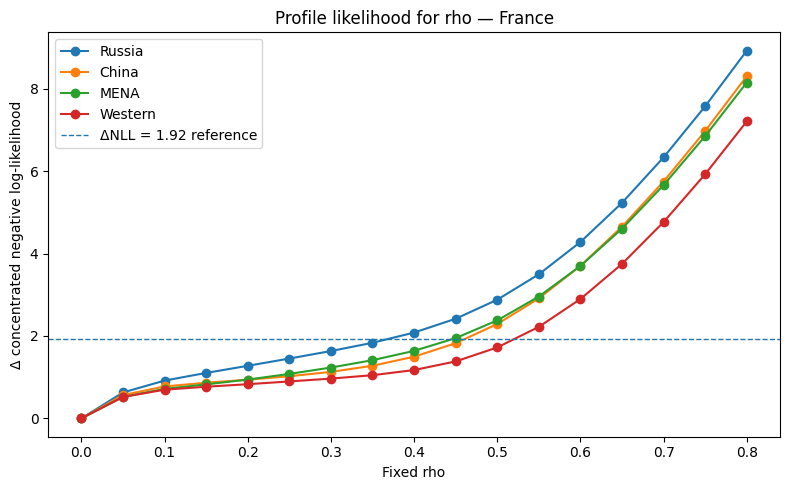

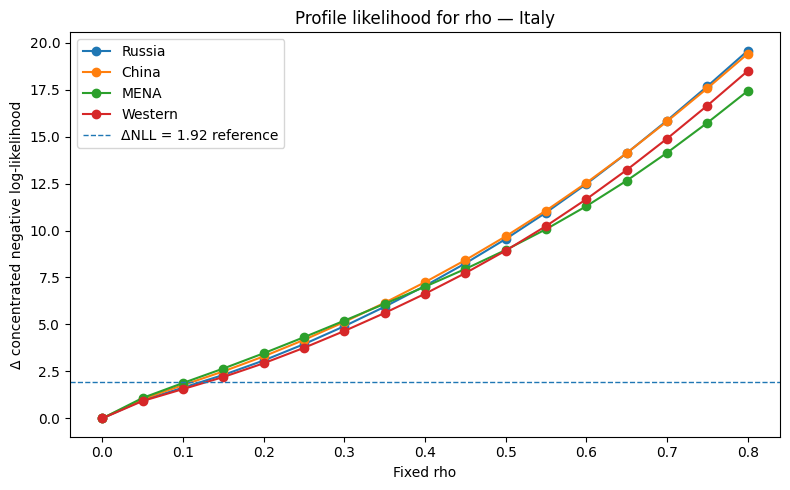

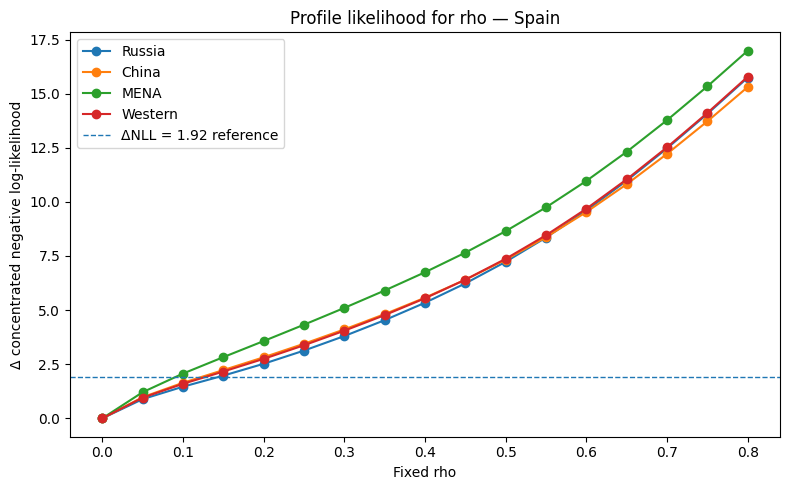

In [7]:
# ============================================================
# E. PROFILE LIKELIHOOD FOR RHO
# ============================================================
RHO_PROFILE_GRID = np.round(np.arange(0.00, 0.81, 0.05), 2)


def concentrated_negloglik_fixed_rho(scales, rho_fixed, Y, quarters, p):
    return concentrated_negloglik(
        np.array([scales[0], scales[1], scales[2], rho_fixed]),
        Y,
        quarters,
        p,
    )


def profile_rho_system(Y, quarters, p, theta_mle, rho_grid=RHO_PROFILE_GRID):
    s0_mle, s1_mle, s2_mle, _ = theta_mle
    bounds = [(SCALE_LOWER, SCALE_UPPER)] * 3
    rows = []

    for rho_fixed in rho_grid:
        starts = [
            np.array([s0_mle, s1_mle, s2_mle]),
            np.array([1.50, 5.00, 5.00]),
            np.array([2.50, 6.00, 8.00]),
            np.array([2.00, 4.00, 9.00]),
        ]
        best = None
        for start in starts:
            res = minimize(
                concentrated_negloglik_fixed_rho,
                x0=start,
                args=(rho_fixed, Y, quarters, p),
                method="L-BFGS-B",
                bounds=bounds,
                options={"maxiter": 2000, "ftol": 1e-12},
            )
            if np.isfinite(res.fun) and (best is None or res.fun < best.fun):
                best = res

        if best is None:
            raise RuntimeError(f"Profile optimisation failed for rho={rho_fixed:.2f}")

        rows.append({
            "rho": float(rho_fixed),
            "profile_nll": float(best.fun),
            "s0_hat": float(best.x[0]),
            "s1_hat": float(best.x[1]),
            "s2_hat": float(best.x[2]),
            "optimizer_success": bool(best.success),
        })

    profile = pd.DataFrame(rows)
    profile["delta_nll"] = profile["profile_nll"] - profile["profile_nll"].min()
    profile["two_delta_nll"] = 2 * profile["delta_nll"]
    return profile


profile_results, profile_rows_all, profile_summary_rows = {}, [], []
CHECK_RHOS = [0.00, 0.10, 0.20, 0.30]

for country in TARGET_COUNTRIES:
    for origin, gpr_col in GPR_ORIGIN_COLS.items():
        df, var_order = system_frame(country, gpr_col)
        Y = df[var_order].to_numpy(dtype=float)
        quarters = df["quarter"].astype(str).reset_index(drop=True)
        theta_mle = theta_results[(country, origin)]["theta_hat"]

        profile = profile_rho_system(Y, quarters, LAG, theta_mle)
        profile_results[(country, origin)] = profile
        rho_profile_min = float(profile.loc[profile["profile_nll"].idxmin(), "rho"])

        for _, row in profile.iterrows():
            profile_rows_all.append({
                "country": country,
                "gpr_origin": origin,
                "rho_mle": float(theta_mle[3]),
                **row.to_dict(),
            })

        summary = {
            "country": country,
            "gpr_origin": origin,
            "rho_MLE": float(theta_mle[3]),
            "rho_profile_min": rho_profile_min,
        }
        for rho_check in CHECK_RHOS:
            match = profile[np.isclose(profile["rho"], rho_check)].iloc[0]
            summary[f"delta_nll_rho_{rho_check:.2f}"] = float(match["delta_nll"])
            summary[f"2delta_nll_rho_{rho_check:.2f}"] = float(match["two_delta_nll"])
        profile_summary_rows.append(summary)

        print(
            f"{country:8s} - {origin:7s} | "
            f"rho_MLE={theta_mle[3]:.3f} | profile minimum={rho_profile_min:.2f}"
        )

rho_profile_all = pd.DataFrame(profile_rows_all)
rho_profile_summary = pd.DataFrame(profile_summary_rows)

rho_profile_all.to_csv(OUTPUT_DIR / "06_profile_rho_all_systems.csv", index=False)
rho_profile_summary.to_csv(OUTPUT_DIR / "07_profile_rho_summary.csv", index=False)

display(rho_profile_summary)
print("Systems with rho_MLE = 0:")
display(
    rho_profile_summary[np.isclose(rho_profile_summary["rho_MLE"], 0.0)][[
        "country", "gpr_origin", "rho_MLE", "rho_profile_min",
        "delta_nll_rho_0.00", "delta_nll_rho_0.10",
        "delta_nll_rho_0.20", "delta_nll_rho_0.30",
    ]]
)

for country in TARGET_COUNTRIES:
    fig, ax = plt.subplots(figsize=(8, 5))
    for origin in ORIGINS:
        profile = profile_results[(country, origin)]
        ax.plot(profile["rho"], profile["delta_nll"], marker="o", label=origin)
    # Visual reference only: rho=0 is a boundary point.
    ax.axhline(1.92, linestyle="--", linewidth=1, label="ΔNLL = 1.92 reference")
    ax.set_title(f"Profile likelihood for rho — {country}")
    ax.set_xlabel("Fixed rho")
    ax.set_ylabel("Δ concentrated negative log-likelihood")
    ax.legend()
    plt.tight_layout()
    plt.savefig(OUTPUT_DIR / f"PROFILE_rho_{country}.png", dpi=150, bbox_inches="tight")
    plt.show()


In [16]:
# ============================================================
# F1. MINNESOTA PRIOR + DRAW HELPERS
# ============================================================
def build_minnesota_prior_mixed(
    s, n, p, gpr_idx, phi_gpr, n_exog=0,
    lam1=LAM1, lam2=LAM2, lam3=LAM3, lam4=LAM4,
    exog_tightness=EXOG_TIGHTNESS,
):
    k = 1 + n * p + n_exog
    B0 = np.zeros(n * k)
    H_diag = np.zeros(n * k)

    for i in range(n):
        base = i * k
        H_diag[base] = (s[i] * lam4) ** 2

        for lag in range(1, p + 1):
            for j in range(n):
                idx = base + 1 + (lag - 1) * n + j
                if j == i:
                    H_diag[idx] = (lam1 / (lag ** lam3)) ** 2
                    if lag == 1 and i == gpr_idx:
                        B0[idx] = phi_gpr
                else:
                    H_diag[idx] = (
                        (s[i] * lam1 * lam2) / (s[j] * (lag ** lam3))
                    ) ** 2

        exog_start = base + 1 + n * p
        for q in range(n_exog):
            H_diag[exog_start + q] = (s[i] * exog_tightness) ** 2

    return B0, np.diag(H_diag)


def safe_cholesky(M, jitter=1e-12, max_tries=8):
    M = (M + M.T) / 2
    for j in range(max_tries):
        try:
            return np.linalg.cholesky(M + (10 ** j) * jitter * np.eye(M.shape[0]))
        except np.linalg.LinAlgError:
            pass
    raise np.linalg.LinAlgError("Cholesky decomposition failed.")


def draw_inverse_wishart(df, scale, rng):
    scale = (scale + scale.T) / 2
    precision = np.linalg.inv(scale)
    L = safe_cholesky(precision)
    A = rng.standard_normal((int(df), scale.shape[0])) @ L.T
    return np.linalg.inv(A.T @ A)


In [17]:
# ============================================================
# F2. GENERAL BVAR GIBBS SAMPLER
# ============================================================
def bvar_minnesota_gibbs(
    Y, quarters, p, gpr_idx, Z=None, scale_path=None,
    reps=REPS, burn=BURN, seed=SEED,
):
    rng = np.random.default_rng(seed)
    T, n = Y.shape

    # Model-specific design.
    X, Ydep = build_var_xy(Y, p, Z=Z)
    T_eff, k = len(Ydep), X.shape[1]

    # FIXED Minnesota residual scales: always from the same
    # unadjusted homoskedastic VAR for this country-origin system.
    X_prior, Ydep_prior = build_var_xy(Y, p, Z=None)
    Beta_prior = np.linalg.lstsq(X_prior, Ydep_prior, rcond=None)[0]
    U_prior = Ydep_prior - X_prior @ Beta_prior
    Sigma_prior = (U_prior.T @ U_prior) / len(Ydep_prior)
    prior_scales = np.sqrt(np.diag(Sigma_prior))

    n_exog = 0 if Z is None else np.asarray(Z).reshape(T, -1).shape[1]

    if scale_path is None:
        full_scale = np.ones(T, dtype=float)
    else:
        full_scale = np.asarray(scale_path, dtype=float)
        if len(full_scale) != T:
            raise ValueError("scale_path must have the same length as Y.")
    s_eff = full_scale[p:]

    X_star = X / s_eff[:, None]
    Y_star = Ydep / s_eff[:, None]
    Beta_wls = np.linalg.lstsq(X_star, Y_star, rcond=None)[0]
    U_star = (Ydep - X @ Beta_wls) / s_eff[:, None]
    Sigma_wls = (U_star.T @ U_star) / T_eff

    phi_gpr = estimate_ar1(Y[:, gpr_idx])
    B0, H = build_minnesota_prior_mixed(
        s=prior_scales,
        n=n,
        p=p,
        gpr_idx=gpr_idx,
        phi_gpr=phi_gpr,
        n_exog=n_exog,
    )

    Hinv = np.linalg.inv(H)
    XtX_star = X_star.T @ X_star
    beta_wls_vec = Beta_wls.T.reshape(-1)
    Sigma = Sigma_wls.copy()

    n_keep = reps - burn
    beta_draws = np.zeros((n_keep, n, k))
    sigma_draws = np.zeros((n_keep, n, n))
    S = SIGMA_PRIOR_SCALE * np.eye(n)

    for it in range(reps):
        SigInv = np.linalg.inv(Sigma)
        data_precision = np.kron(SigInv, XtX_star)
        post_precision = Hinv + data_precision
        V = np.linalg.inv(post_precision)
        V = (V + V.T) / 2
        M = V @ (Hinv @ B0 + data_precision @ beta_wls_vec)

        beta_vec = M + safe_cholesky(V) @ rng.standard_normal(n * k)
        Beta = beta_vec.reshape(n, k).T

        U_star_it = (Ydep - X @ Beta) / s_eff[:, None]
        posterior_scale = U_star_it.T @ U_star_it + S
        posterior_df = T_eff + ALPHA
        Sigma = draw_inverse_wishart(
            df=posterior_df,
            scale=posterior_scale,
            rng=rng,
        )

        if it >= burn:
            beta_draws[it - burn] = Beta.T
            sigma_draws[it - burn] = Sigma

    return {
        "beta_draws": beta_draws,
        "sigma_draws": sigma_draws,
        "phi_gpr": phi_gpr,
        "scale_path": full_scale,
        "n_exog": n_exog,
        "prior_scales": prior_scales,
    }


In [18]:
# ============================================================
# F3. STRUCTURAL IRF HELPERS
# ============================================================
def phis_from_beta(Beta_T, n, p):
    return [
        Beta_T[:, 1 + lag * n:1 + (lag + 1) * n]
        for lag in range(p)
    ]


def compute_structural_irfs(Phis, Sigma, horizon, n, p):
    Psi = [np.eye(n)]
    for h in range(1, horizon + 1):
        psi_h = np.zeros((n, n))
        for lag in range(1, min(h, p) + 1):
            psi_h += Phis[lag - 1] @ Psi[h - lag]
        Psi.append(psi_h)

    Q = np.linalg.cholesky(Sigma)
    return np.array([psi @ Q for psi in Psi])


def bvar_structural_irfs(beta_draws, sigma_draws, n, p, horizon):
    out = np.zeros((beta_draws.shape[0], horizon + 1, n, n))
    for d in range(beta_draws.shape[0]):
        Phis = phis_from_beta(beta_draws[d], n, p)
        out[d] = compute_structural_irfs(Phis, sigma_draws[d], horizon, n, p)
    return out


In [19]:
# ============================================================
# G1. ESTIMATE THE THREE COVID TREATMENTS — 16 SYSTEMS
# ============================================================
homoskedastic_results, dummy_results, truncated_results = {}, {}, {}
system_counter = 0

for country in TARGET_COUNTRIES:
    for origin, gpr_col in GPR_ORIGIN_COLS.items():
        df, var_order = system_frame(country, gpr_col)
        Y = df[var_order].to_numpy(dtype=float)
        quarters = df["quarter"].astype(str).reset_index(drop=True)
        Z_covid = build_covid_dummies(quarters)

        s0, s1, s2, rho = theta_results[(country, origin)]["theta_hat"]
        scale_path = build_truncated_covid_scale_path(quarters, s0, s1, s2, rho)
        system_counter += 1

        hom = bvar_minnesota_gibbs(
            Y, quarters, LAG, 0,
            Z=None, scale_path=None,
            reps=REPS, burn=BURN, seed=SEED,
        )
        dum = bvar_minnesota_gibbs(
            Y, quarters, LAG, 0,
            Z=Z_covid, scale_path=None,
            reps=REPS, burn=BURN, seed=SEED,
        )
        tru = bvar_minnesota_gibbs(
            Y, quarters, LAG, 0,
            Z=None, scale_path=scale_path,
            reps=REPS, burn=BURN, seed=SEED,
        )

        # Ceteris-paribus checks.
        assert np.allclose(hom["prior_scales"], dum["prior_scales"]), (
            f"Prior scales differ: {country}-{origin}, hom vs dummy"
        )
        assert np.allclose(hom["prior_scales"], tru["prior_scales"]), (
            f"Prior scales differ: {country}-{origin}, hom vs truncated"
        )
        assert np.isclose(hom["phi_gpr"], dum["phi_gpr"])
        assert np.isclose(hom["phi_gpr"], tru["phi_gpr"])

        irf_hom = bvar_structural_irfs(
            hom["beta_draws"], hom["sigma_draws"], 6, LAG, IRF_HORIZON
        )
        irf_dum = bvar_structural_irfs(
            dum["beta_draws"], dum["sigma_draws"], 6, LAG, IRF_HORIZON
        )
        irf_tru = bvar_structural_irfs(
            tru["beta_draws"], tru["sigma_draws"], 6, LAG, IRF_HORIZON
        )

        homoskedastic_results[(country, origin)] = (irf_hom, hom["phi_gpr"], var_order)
        dummy_results[(country, origin)] = (irf_dum, dum["phi_gpr"], var_order)
        truncated_results[(country, origin)] = (irf_tru, tru["phi_gpr"], var_order)

        print(
            f"{country:8s} - {origin:7s} | "
            "homoskedastic + dummies + truncated completed | prior scales OK"
        )

print(f"\nCompleted {len(homoskedastic_results)} systems for each model.")
print("Minnesota prior-scale sanity check passed for all 16 systems.")


Germany  - Russia  | homoskedastic + dummies + truncated completed | prior scales OK
Germany  - China   | homoskedastic + dummies + truncated completed | prior scales OK
Germany  - MENA    | homoskedastic + dummies + truncated completed | prior scales OK
Germany  - Western | homoskedastic + dummies + truncated completed | prior scales OK
France   - Russia  | homoskedastic + dummies + truncated completed | prior scales OK
France   - China   | homoskedastic + dummies + truncated completed | prior scales OK
France   - MENA    | homoskedastic + dummies + truncated completed | prior scales OK
France   - Western | homoskedastic + dummies + truncated completed | prior scales OK
Italy    - Russia  | homoskedastic + dummies + truncated completed | prior scales OK
Italy    - China   | homoskedastic + dummies + truncated completed | prior scales OK
Italy    - MENA    | homoskedastic + dummies + truncated completed | prior scales OK
Italy    - Western | homoskedastic + dummies + truncated complete

In [20]:
# ============================================================
# G2. GPR AR(1) PRIOR MEANS
# ============================================================
phi_rows = []
for country in TARGET_COUNTRIES:
    for origin, gpr_col in GPR_ORIGIN_COLS.items():
        phi_rows.append({
            "country": country,
            "gpr_origin": origin,
            "phi_gpr_AR1": float(homoskedastic_results[(country, origin)][1]),
        })

phi_gpr_table = pd.DataFrame(phi_rows)
phi_gpr_pivot = (
    phi_gpr_table.pivot(index="country", columns="gpr_origin", values="phi_gpr_AR1")
    .reindex(index=TARGET_COUNTRIES, columns=ORIGINS)
)

print("GPR AR(1) prior means — country × origin:")
display(phi_gpr_pivot)
phi_gpr_table.to_csv(OUTPUT_DIR / "08_GPR_AR1_prior_means.csv", index=False)


GPR AR(1) prior means — country × origin:


gpr_origin,Russia,China,MENA,Western
country,,,,
Germany,0.906100,0.833388,0.693985,0.872792
France,0.877628,0.870367,0.808851,0.851218
Italy,0.793868,0.775831,0.502464,0.737524
Spain,0.786816,0.719157,0.498014,0.587008


In [21]:
# ============================================================
# G3. IRF SYNTHESIS + PAIRWISE COMPARISON
# ============================================================
HORIZONS = {"impact": 0, "1yr": 4}


def build_synthesis(results, model_name):
    rows = []
    for (country, origin), (irfs, phi_gpr, var_order) in results.items():
        med = np.median(irfs, axis=0)
        lo = np.percentile(irfs, CI_LOW_68, axis=0)
        hi = np.percentile(irfs, CI_HIGH_68, axis=0)

        for response_idx, response_var in enumerate(var_order[1:], start=1):
            for h_name, h in HORIZONS.items():
                median = med[h, response_idx, 0]
                low = lo[h, response_idx, 0]
                high = hi[h, response_idx, 0]
                rows.append({
                    "model": model_name,
                    "country": country,
                    "gpr_origin": origin,
                    "response_var": response_var,
                    "horizon": h_name,
                    "median": float(median),
                    "low68": float(low),
                    "high68": float(high),
                    "sign": int(np.sign(median)),
                    "significant_68": bool((low > 0) or (high < 0)),
                    "credible_width": float(high - low),
                })
    return pd.DataFrame(rows)


syn_hom = build_synthesis(homoskedastic_results, "homoskedastic")
syn_dummy = build_synthesis(dummy_results, "covid_dummies")
syn_truncated = build_synthesis(truncated_results, "truncated_two_stage")
all_synthesis = pd.concat([syn_hom, syn_dummy, syn_truncated], ignore_index=True)
all_synthesis.to_csv(OUTPUT_DIR / "09_three_model_irf_synthesis.csv", index=False)

KEYS = ["country", "gpr_origin", "response_var", "horizon"]


def pairwise_model_comparison(syn_a, syn_b, name_a, name_b):
    comp = (
        syn_a.drop(columns=["model"])
        .merge(
            syn_b.drop(columns=["model"]),
            on=KEYS,
            suffixes=(f"_{name_a}", f"_{name_b}"),
        )
    )
    comp["same_sign"] = comp[f"sign_{name_a}"] == comp[f"sign_{name_b}"]
    comp["significance_changed"] = (
        comp[f"significant_68_{name_a}"] != comp[f"significant_68_{name_b}"]
    )
    comp["gain_in_b"] = (~comp[f"significant_68_{name_a}"]) & comp[f"significant_68_{name_b}"]
    comp["loss_in_b"] = comp[f"significant_68_{name_a}"] & (~comp[f"significant_68_{name_b}"])
    comp["width_ratio_b_over_a"] = (
        comp[f"credible_width_{name_b}"] /
        comp[f"credible_width_{name_a}"].replace(0, np.nan)
    )

    summary = {
        "comparison": f"{name_a} -> {name_b}",
        "cells": len(comp),
        "sign_agreement_pct": 100 * comp["same_sign"].mean(),
        "significance_changes": int(comp["significance_changed"].sum()),
        "gains_in_second_model": int(comp["gain_in_b"].sum()),
        "losses_in_second_model": int(comp["loss_in_b"].sum()),
        "median_width_ratio_second_over_first": float(comp["width_ratio_b_over_a"].median()),
    }
    return comp, summary


comp_hom_dummy, s_hom_dummy = pairwise_model_comparison(syn_hom, syn_dummy, "hom", "dummy")
comp_hom_tru, s_hom_tru = pairwise_model_comparison(syn_hom, syn_truncated, "hom", "truncated")
comp_dummy_tru, s_dummy_tru = pairwise_model_comparison(syn_dummy, syn_truncated, "dummy", "truncated")

pairwise_summary = pd.DataFrame([s_hom_dummy, s_hom_tru, s_dummy_tru])
display(pairwise_summary)
pairwise_summary.to_csv(OUTPUT_DIR / "10_pairwise_model_comparison_summary.csv", index=False)
comp_hom_dummy.to_csv(OUTPUT_DIR / "11_hom_vs_dummy_cells.csv", index=False)
comp_hom_tru.to_csv(OUTPUT_DIR / "12_hom_vs_truncated_cells.csv", index=False)
comp_dummy_tru.to_csv(OUTPUT_DIR / "13_dummy_vs_truncated_cells.csv", index=False)


,comparison,cells,sign_agreement_pct,significance_changes,gains_in_second_model,losses_in_second_model,median_width_ratio_second_over_first
0,hom -> dummy,160,91.250,19,15,4,0.998106
1,hom -> truncated,160,86.875,20,14,6,0.971133
2,dummy -> truncated,160,95.625,11,4,7,0.968740


In [22]:
# ============================================================
# H. FINAL SANITY CHECKS
# ============================================================
boundary_profile_ok = bool(
    np.allclose(
        rho_profile_summary.loc[
            np.isclose(rho_profile_summary["rho_MLE"], 0.0),
            "rho_profile_min",
        ],
        0.0,
    )
)

checks = {
    "16 theta estimates": len(theta_table) == 16,
    "all MLE optimizers report success": bool(theta_table["optimizer_success"].all()),
    "all MLE objectives finite": bool(np.isfinite(theta_table["objective"]).all()),
    "all scale parameters >= 1": bool((theta_table[["s0_2020Q1", "s1_2020Q2", "s2_2020Q3"]] >= 1).all().all()),
    "all rho in [0,1)": bool(((theta_table["rho"] >= 0) & (theta_table["rho"] < 1)).all()),
    "all paths equal 1 from 2021Q4 onward": bool(np.allclose(
        scale_paths.loc[scale_paths["quarter"] >= "2021Q4", "s_t"], 1.0
    )),
    "all profile objectives finite": bool(np.isfinite(rho_profile_all["profile_nll"]).all()),
    "boundary rho profile minima are at zero": boundary_profile_ok,
    "16 GPR AR(1) prior means": len(phi_gpr_table) == 16,
    "all GPR AR(1) prior means inside (-1,1)": bool((phi_gpr_table["phi_gpr_AR1"].abs() < 1).all()),
    "160 IRF cells per model": all(len(x) == 160 for x in [syn_hom, syn_dummy, syn_truncated]),
}

checks_table = pd.DataFrame({"check": list(checks.keys()), "passed": list(checks.values())})
display(checks_table)

if not checks_table["passed"].all():
    raise RuntimeError("At least one final NB04 sanity check failed. Do not freeze production files.")

print("All final NB04 sanity checks passed.")


,check,passed
0,16 theta estimates,True
1,all MLE optimizers report success,True
2,all MLE objectives finite,True
3,all scale parameters >= 1,True
4,"all rho in [0,1)",True
5,all paths equal 1 from 2021Q4 onward,True
6,all profile objectives finite,True
7,boundary rho profile minima are at zero,True
8,16 GPR AR(1) prior means,True
9,"all GPR AR(1) prior means inside (-1,1)",True


All final NB04 sanity checks passed.


In [23]:
# ============================================================
# I. EXPORT PRODUCTION COVID INPUTS
# ============================================================
production_theta = theta_table[[
    "country", "gpr_origin", "s0_2020Q1", "s1_2020Q2", "s2_2020Q3", "rho"
]].copy()

production_paths = scale_paths[[
    "country", "gpr_origin", "quarter", "s_t"
]].copy()

production_theta.to_csv(
    OUTPUT_DIR / "PRODUCTION_covid_theta_mle.csv",
    index=False,
)
production_paths.to_csv(
    OUTPUT_DIR / "PRODUCTION_covid_scale_paths.csv",
    index=False,
)

print("Production files saved:")
print(OUTPUT_DIR / "PRODUCTION_covid_theta_mle.csv")
print(OUTPUT_DIR / "PRODUCTION_covid_scale_paths.csv")


Production files saved:
/content/drive/MyDrive/TFM_GitHub/outputs/04_covid_volatility/PRODUCTION_covid_theta_mle.csv
/content/drive/MyDrive/TFM_GitHub/outputs/04_covid_volatility/PRODUCTION_covid_scale_paths.csv


## J. Final methodological decision

**Production treatment:** two-stage truncated volatility, with the COVID volatility parameters estimated by concentrated maximum likelihood.

- The reduced-form diagnostics identify 2020Q2–2020Q3 as exceptional innovation-variance observations across the 16 systems.
- The profile likelihood supports heterogeneous post-pandemic volatility persistence across recipient economies. Boundary estimates of `rho = 0` are treated as valid maximum-likelihood solutions rather than numerical failures.
- No informative prior is imposed on the COVID volatility parameters in the production specification. The estimated scale paths are determined by the concentrated likelihood and subsequently treated as fixed inputs in the BVAR estimation.
- The deterministic COVID-dummy specification is retained as a comparison model. Date-specific residual reductions are descriptive and are not used mechanically as a model-selection criterion.
- The three-model comparison is conducted ceteris paribus: sample, lag length, Minnesota hyperparameters, covariance prior, recursive ordering, posterior draws and IRF horizons are held fixed across COVID treatments.
- The frozen maximum-likelihood volatility paths exported by this notebook are the COVID inputs used by the downstream production BVAR in notebook 05.

The purpose of this notebook is therefore limited to diagnosing exceptional pandemic volatility, comparing the three COVID treatments, and freezing the selected volatility adjustment. The main BVAR results and geographical-heterogeneity analysis are reported downstream.
